# Graphs, schedules and measured profiles

Render an actual Caustics image and inspect its Caskade ownership graph.
Then use a small two-region simulator to make the captured tensor graph
and device lanes readable. With two CUDA devices, the source is assigned
to GPU 1 and the root to GPU 0. CPU and one-GPU installations run the
same examples on their available home.

```{eval-rst}
:download:`Download notebook <visualization.ipynb>`
```

| View | Shows | Does not establish |
| --- | --- | --- |
| `draw_model` | Caskade ownership, parameters, ties and assigned homes | Kernel timing or overlap |
| `draw_execution` | Captured tensor dependencies, scopes, shapes and devices | Measured runtime order |
| `draw_schedule` | Dependency levels on device lanes | Durations or simultaneous execution |
| `profile` | A measured Torch CPU/CUDA trace | A universal performance result |

Run this notebook from the project root, or [download the example helpers](../_static/niagara-example-helpers.zip) and extract them beside a downloaded notebook. The helpers are examples, not part of the Niagara wheel.


In [1]:
import importlib.util
import json
import shutil
from collections import Counter

import torch

import niagara as ng

missing = [
    name
    for name in ("caustics", "matplotlib", "graphviz")
    if importlib.util.find_spec(name) is None
]
READY = not missing
HAS_DOT = shutil.which("dot") is not None
if not READY:
    print("SKIPPED: install Niagara's full extra; missing", missing)
else:
    get_ipython().run_line_magic("matplotlib", "inline")
    import caskade as ck
    import matplotlib.pyplot as plt
    from IPython.display import SVG, display

    from examples.niagara_examples.caustics import image_problem

    home = "cuda:0" if torch.cuda.is_available() else "cpu"
    source_home = "cuda:1" if torch.cuda.device_count() >= 2 else home
    print(
        json.dumps(
            {"root_device": home, "source_device": source_home, "graphviz_dot": HAS_DOT}, indent=2
        )
    )
    if not HAS_DOT:
        print("SVG graphs skipped: install Graphviz and add its dot executable to PATH.")

{
  "root_device": "cuda:0",
  "source_device": "cuda:1",
  "graphviz_dot": true
}


## A classic simulator and its ownership

The image below uses SIE mass, external shear, source and lens-light
Sersic profiles and a PSF. Its 21 packed physical parameters are unchanged
by placement. The device assertions and numerical comparison check execution alongside
the picture. The ownership diagram describes the model structure.


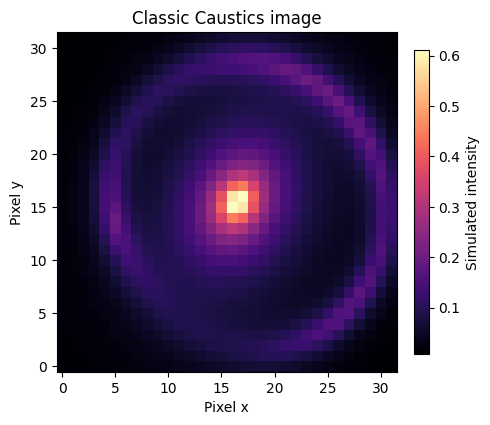

{
  "shape": [
    32,
    32
  ],
  "output_device": "cuda:0",
  "source_parameter_device": "cuda:1",
  "max_abs_error": 0.0
}


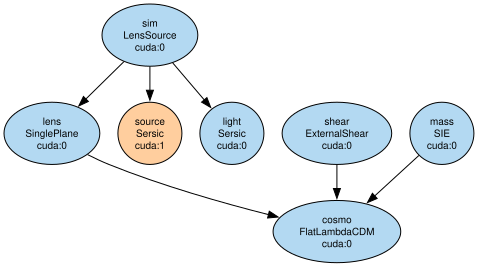

In [2]:
if READY:
    problem = image_problem(32, device=home)
    reference = problem.model(problem.truth).detach()
    modules = {"source": source_home} if source_home != home else {}
    placement = ng.assign_devices(problem.model, ng.DevicePlan(home, modules))
    image = problem.model(problem.truth)
    assert str(image.device) == home
    assert str(problem.model.source.Re.device) == source_home
    torch.testing.assert_close(image, reference, rtol=1e-9, atol=1e-10)

    fig, ax = plt.subplots(figsize=(4.8, 4.2), constrained_layout=True)
    im = ax.imshow(image.detach().cpu(), origin="lower", cmap="magma")
    ax.set_title("Classic Caustics image")
    ax.set_xlabel("Pixel x")
    ax.set_ylabel("Pixel y")
    fig.colorbar(im, ax=ax, label="Simulated intensity", shrink=0.85)
    plt.show()
    print(
        json.dumps(
            {
                "shape": list(image.shape),
                "output_device": str(image.device),
                "source_parameter_device": str(problem.model.source.Re.device),
                "max_abs_error": float((image - reference).abs().max()),
            },
            indent=2,
        )
    )
    if HAS_DOT:
        graph = ng.draw_model(problem.model, parameters=False, devices=True, rankdir="TB")
        display(SVG(data=graph.pipe(format="svg").decode("utf-8")))
    placement.close()
    ng.assign_devices(problem.model, ng.DevicePlan(home)).close()

The displayed graph is the actual module DAG. Shared cosmology nodes
remain shared; the source region has its declared home. Parameters are
hidden for readability. Set `parameters=True` to include their nodes
and tied-parameter annotations.

## A compact captured tensor graph

This small simulator scales a fixed Gaussian template in its source
region, then adds a background at the root. Its two dynamic
parameters make transfers and dependencies easy to inspect. The
preceding image uses the full classic Caustics workload. This compact
example makes the structure readable; it supplies no performance
comparison for that workload.


{
  "output_shape": [
    8,
    8
  ],
  "output_device": "cuda:0",
  "source_parameter_device": "cuda:1",
  "captured_nodes": 11,
  "nodes_per_device": {
    "cuda:0": 5,
    "cuda:1": 5
  }
}


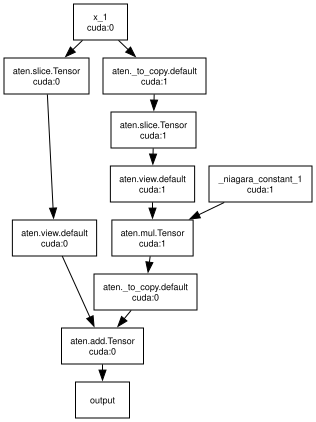

In [3]:
if READY:

    class TemplateSource(ck.Module):
        def __init__(self):
            super().__init__("source")
            self.flux = ck.Param("flux", None)

        @ck.forward
        def __call__(self, template, flux):
            return template * flux

    class CompactImage(ck.Module):
        def __init__(self):
            super().__init__("compact")
            self.source = TemplateSource()
            self.background = ck.Param("background", None)
            axis = torch.linspace(-1, 1, 8, dtype=torch.float64)
            yy, xx = torch.meshgrid(axis, axis, indexing="ij")
            self._template = torch.exp(-4 * (xx.square() + yy.square()))

        @ck.forward
        def __call__(self, background):
            return self.source(self._template) + background

    compact = CompactImage().to(dtype=torch.float64)
    parameter_values = {compact.source.flux: 1.1, compact.background: 0.05}
    parameters = torch.tensor(
        [parameter_values[param] for param in compact.dynamic_params], dtype=torch.float64
    )
    compact_reference = compact(parameters).detach()
    compact_placement = ng.assign_devices(compact, ng.DevicePlan(home, modules))
    parameters = parameters.to(home)
    compiled = ng.compile_model(compact, parameters, backend="eager", record_scopes=True)
    compact_image = compiled(parameters)
    assert str(compact_image.device) == home
    assert str(compact.source.flux.device) == source_home
    torch.testing.assert_close(compact_image.cpu(), compact_reference, rtol=1e-12, atol=1e-12)
    nodes = compiled.execution_plan()["nodes"]
    print(
        json.dumps(
            {
                "output_shape": list(compact_image.shape),
                "output_device": str(compact_image.device),
                "source_parameter_device": str(compact.source.flux.device),
                "captured_nodes": len(nodes),
                "nodes_per_device": dict(
                    Counter(node["device"] for node in nodes if node["device"])
                ),
            },
            indent=2,
        )
    )
    if HAS_DOT:
        graph = ng.draw_execution(compiled, scopes=False, devices=True, shapes=False, rankdir="TB")
        graph.attr(ranksep="0.25", nodesep="0.2")
        display(SVG(data=graph.pipe(format="svg").decode("utf-8")))

`draw_execution` renders the captured program, including tensor copies
when two homes are used. Device labels come from captured metadata.
Scope and shape labels can be enabled independently. Rendering a graph
does not change the simulator or its placement.

## Device lanes and dependency levels

Every point in the next plot is a captured operation. Its horizontal
position shows a dependency level. Operations on the same level may be
ready together; the plot measures neither elapsed time nor kernel
overlap. A one-home run naturally has only one device lane.


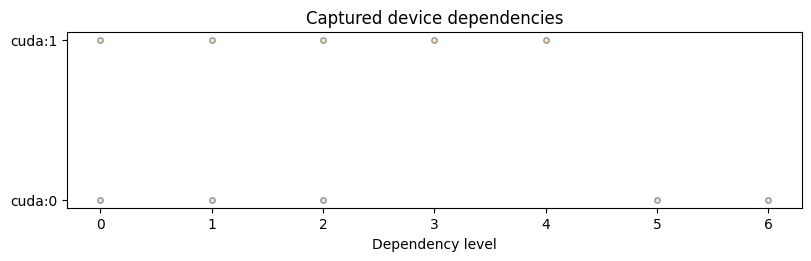

In [4]:
if READY:
    figure = ng.draw_schedule(compiled)
    figure.axes[0].set_title("Captured device dependencies")
    plt.show()
    compact_placement.close()
    ng.assign_devices(compact, ng.DevicePlan(home)).close()

## Measure execution separately

Graph rendering requires both the Python `graphviz` package and the
external Graphviz `dot` executable. Matplotlib supplies the schedule
and scientific plots. They are optional dependencies of the tensor
runtime.

For a prepared program that is still open, the public profiler API is:

```python
ng.profile(compiled, (parameters,), "results/trace.json")
```

This notebook closes its placement handles after displaying the
figures, so prepare a fresh program before profiling. Inspect kernels
on the intended physical devices, copies, waits and both forward and
backward work. Tracing adds overhead; use separate warmed wall-clock
trials for runtime comparisons.

`ng.gallery(sim, output_directory, compiled=compiled)` renders the
supported ownership and execution view options for a prepared model.
Device labels describe the captured structure. Use the profiler to check
activity and timing on those devices.
